In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("/content/Automobile_data (1).csv")

In [4]:
df.head()

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,?,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   body-style         205 non-null    object 
 5   drive-wheels       205 non-null    object 
 6   engine-location    205 non-null    object 
 7   width              205 non-null    float64
 8   height             205 non-null    float64
 9   engine-type        205 non-null    object 
 10  engine-size        205 non-null    int64  
 11  horsepower         205 non-null    object 
 12  city-mpg           205 non-null    int64  
 13  highway-mpg        205 non-null    int64  
 14  price              205 non-null    int64  
dtypes: float64(2), int64(5), object(8)
memory usage: 24.2+ KB


In [6]:
df.describe()

,symboling,width,height,engine-size,city-mpg,highway-mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,65.907805,53.724878,126.907317,25.219512,30.751220,13227.478049
std,1.245307,2.145204,2.443522,41.642693,6.542142,6.886443,7902.651615
min,-2.000000,60.300000,47.800000,61.000000,13.000000,16.000000,5118.000000
25%,0.000000,64.100000,52.000000,97.000000,19.000000,25.000000,7788.000000
50%,1.000000,65.500000,54.100000,120.000000,24.000000,30.000000,10345.000000
75%,2.000000,66.900000,55.500000,141.000000,30.000000,34.000000,16500.000000
max,3.000000,72.300000,59.800000,326.000000,49.000000,54.000000,45400.000000


<Axes: >

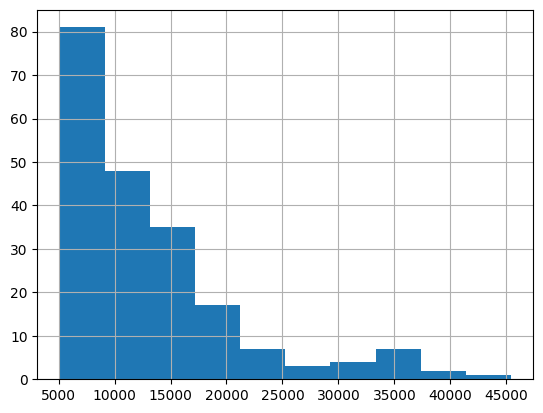

In [7]:
df['price'].hist()

<Axes: >

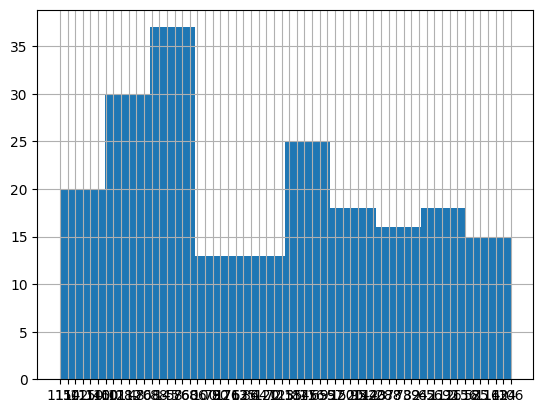

In [8]:
df['horsepower'].hist()

<Axes: >

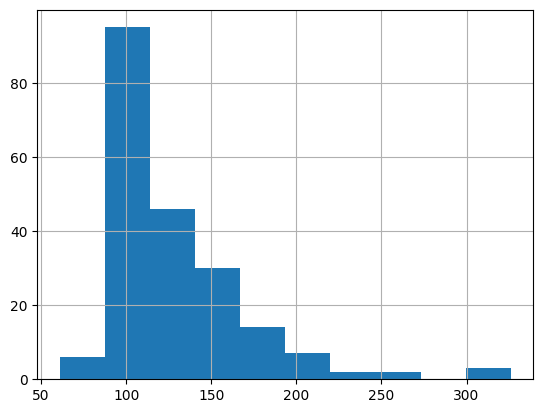

In [9]:
df['engine-size'].hist()

<Axes: >

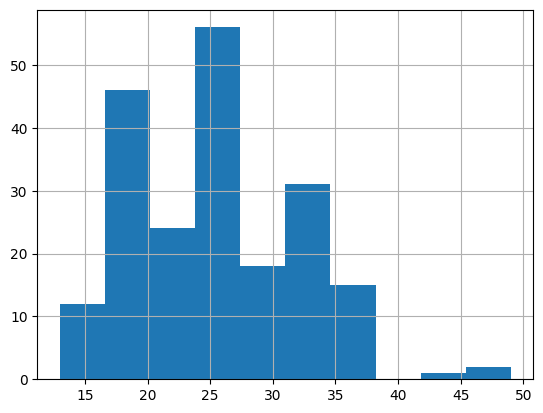

In [10]:
df['city-mpg'].hist()

In [11]:
df.replace("?",np.nan,inplace = True)

In [12]:
df["normalized-losses"] = pd.to_numeric(
df["normalized-losses"],
errors = "coerce"
)
df["horsepower"] = pd.to_numeric(
df["horsepower"],
errors = "coerce"
)

In [13]:
df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


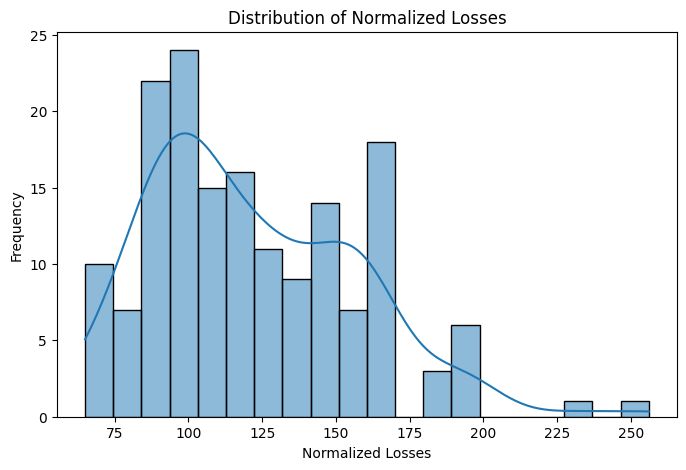

Skewness of Normalized Losses: 0.766


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='normalized-losses',
    bins=20,
    kde=True
)

plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')

plt.show()

# Skewness Value
print("Skewness of Normalized Losses:",
      round(df['normalized-losses'].skew(), 3))

In [15]:
df['normalized-losses'].fillna(
    df['normalized-losses'].median(),
    inplace=True
)

/tmp/ipykernel_3218/390440073.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['normalized-losses'].fillna(


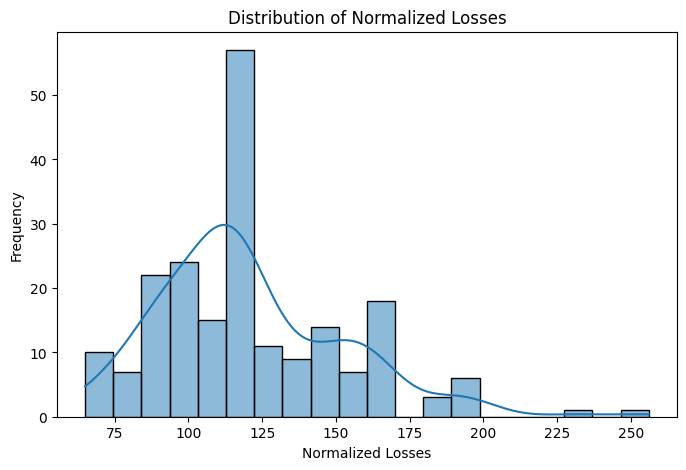

Skewness of Normalized Losses: 0.976


In [16]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='normalized-losses',
    bins=20,
    kde=True
)

plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')

plt.show()

# Skewness Value
print("Skewness of Normalized Losses:",
      round(df['normalized-losses'].skew(), 3))

In [17]:
df['horsepower'].fillna(
    df['horsepower'].median(),
    inplace=True
)

/tmp/ipykernel_3218/2085030141.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].fillna(


In [18]:
df.isnull().sum()

,0
symboling,0
normalized-losses,0
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


In [19]:
df.duplicated().sum()

np.int64(0)

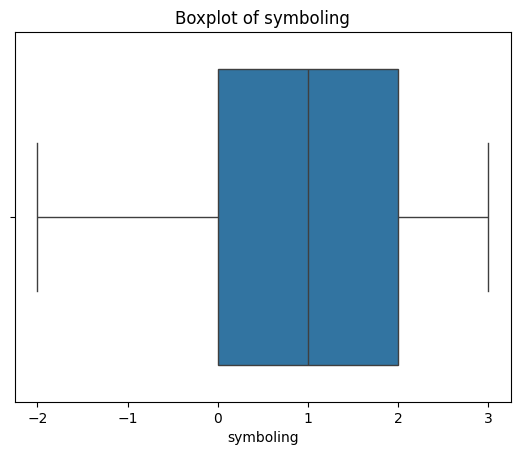

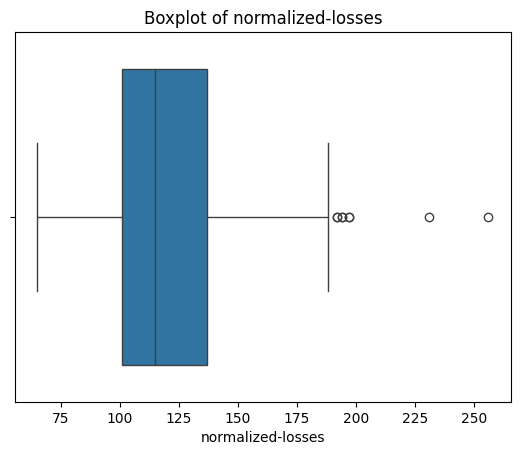

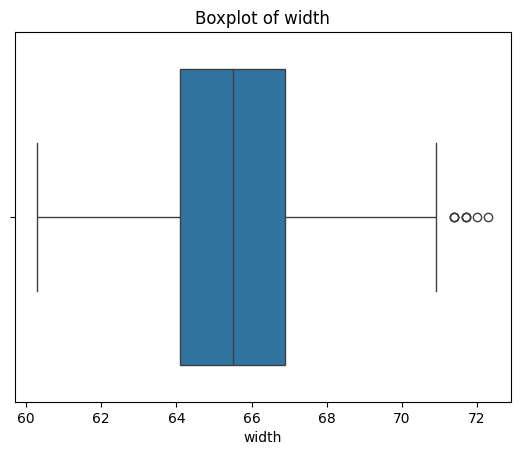

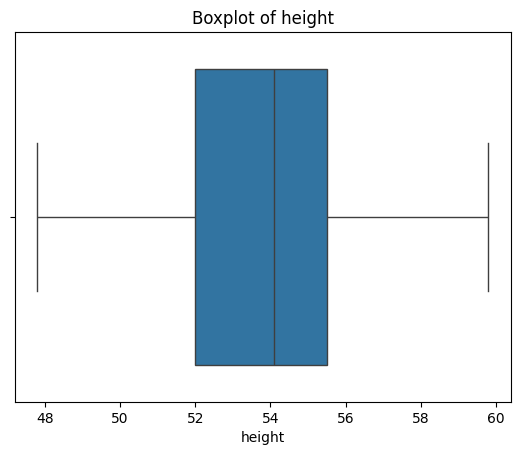

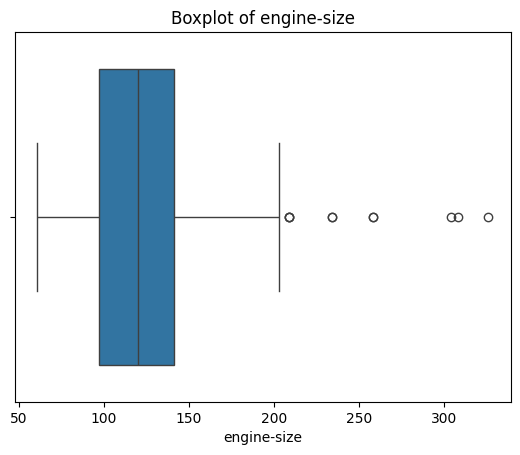

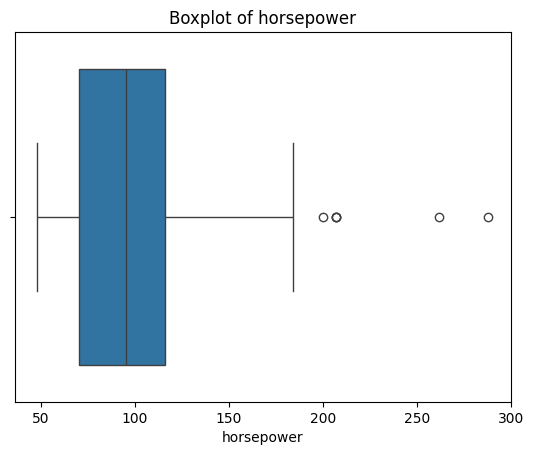

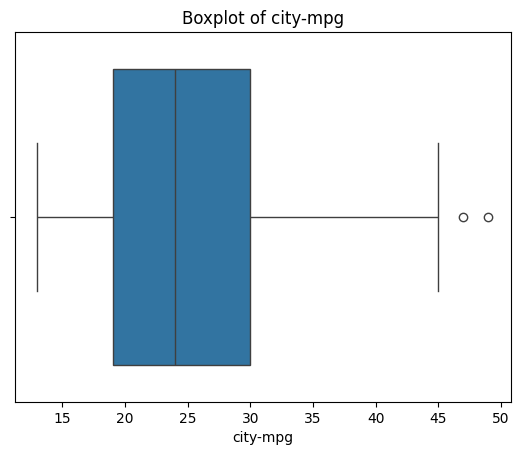

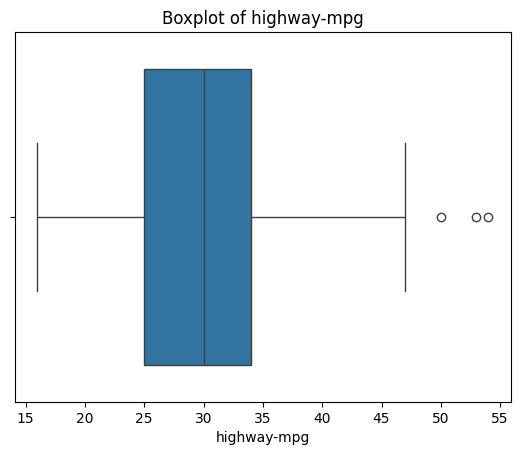

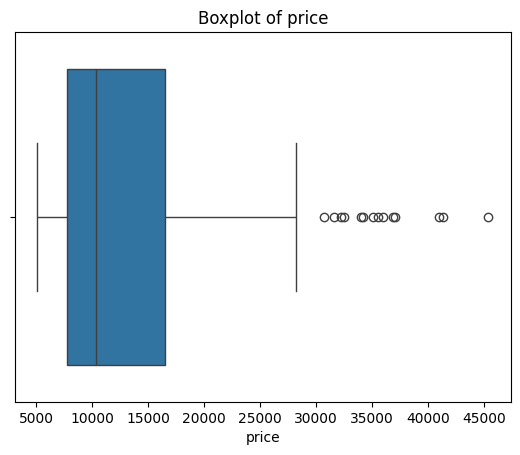

In [20]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    data = df[col].dropna()
    sns.boxplot(x=data)
    plt.title(f'Boxplot of {col}')
    plt.show()

In [21]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df = df[
        (df[col] >= lower_bound) &
        (df[col] <= upper_bound)
    ]

print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (169, 15)


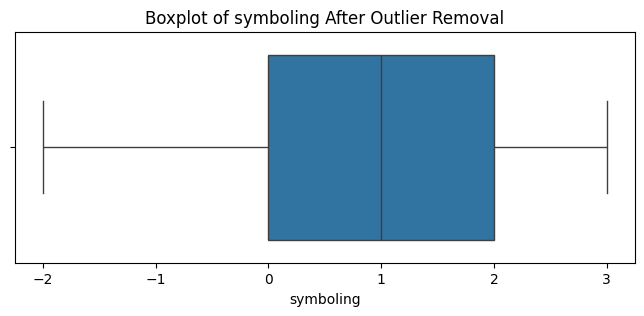

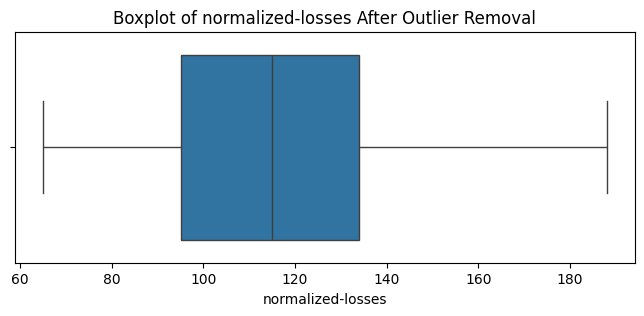

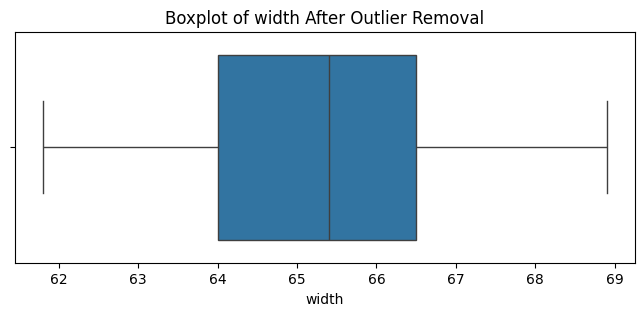

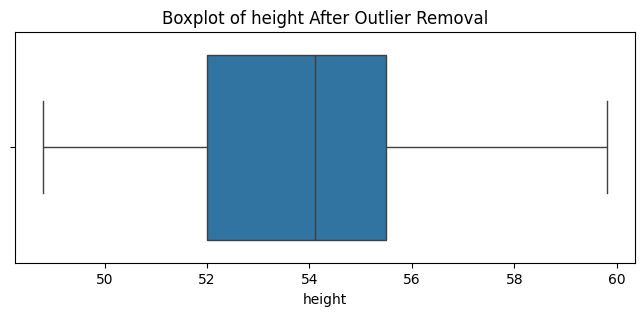

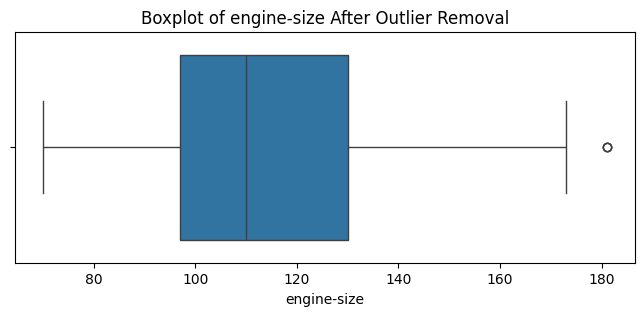

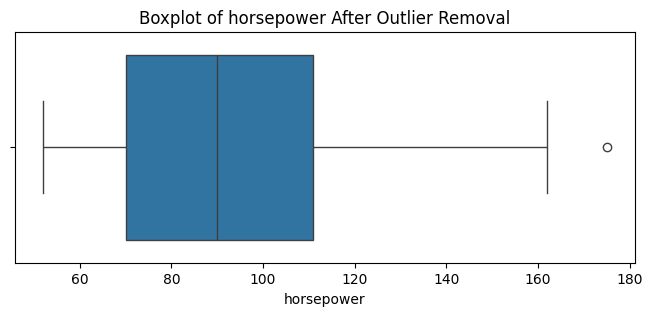

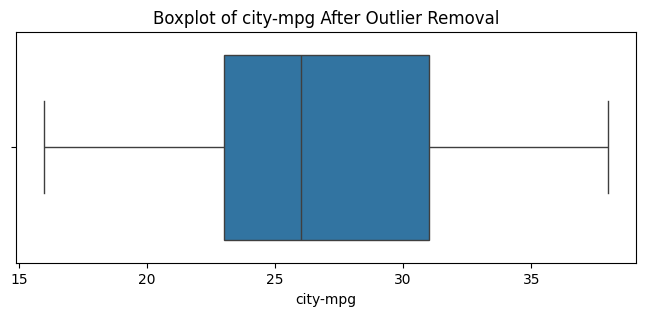

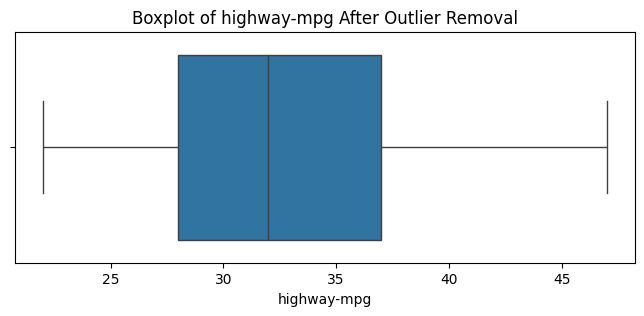

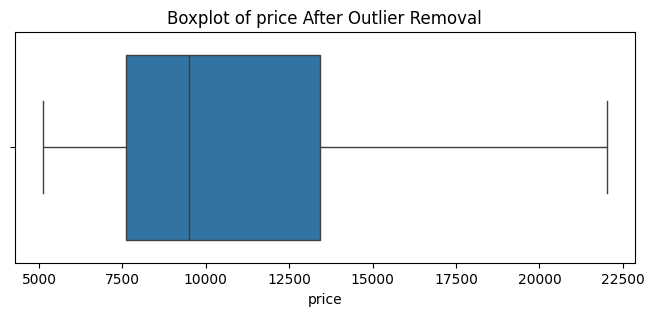

In [22]:
for col in num_cols:

    plt.figure(figsize=(8,3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col} After Outlier Removal')

    plt.show()

In [23]:
df_num=df.select_dtypes(["int64","float64"])
df_cat=df.select_dtypes(object)

In [24]:
df_cat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 169 entries, 0 to 202
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   make             169 non-null    object
 1   fuel-type        169 non-null    object
 2   body-style       169 non-null    object
 3   drive-wheels     169 non-null    object
 4   engine-location  169 non-null    object
 5   engine-type      169 non-null    object
dtypes: object(6)
memory usage: 9.2+ KB


In [25]:
from sklearn.preprocessing import LabelEncoder

for col in df_cat:
    le = LabelEncoder()
    df_cat[col] = le.fit_transform(df_cat[col])

ML LAB 3 CONTINUE

In [26]:
df.corr(numeric_only=True)

,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price
symboling,1.000000,0.417570,-0.229370,-0.517165,-0.174551,0.022640,-0.060090,0.009688,-0.099445
normalized-losses,0.417570,1.000000,0.073477,-0.340202,0.059509,0.146022,-0.196142,-0.139595,0.202649
width,-0.229370,0.073477,1.000000,0.362591,0.650123,0.584367,-0.574829,-0.582006,0.733401
height,-0.517165,-0.340202,0.362591,1.000000,0.221903,-0.004360,-0.068401,-0.121424,0.245356
engine-size,-0.174551,0.059509,0.650123,0.221903,1.000000,0.719068,-0.588434,-0.586582,0.706685
horsepower,0.022640,0.146022,0.584367,-0.004360,0.719068,1.000000,-0.835068,-0.811776,0.747790
city-mpg,-0.060090,-0.196142,-0.574829,-0.068401,-0.588434,-0.835068,1.000000,0.966105,-0.702129
highway-mpg,0.009688,-0.139595,-0.582006,-0.121424,-0.586582,-0.811776,0.966105,1.000000,-0.684707
price,-0.099445,0.202649,0.733401,0.245356,0.706685,0.747790,-0.702129,-0.684707,1.000000


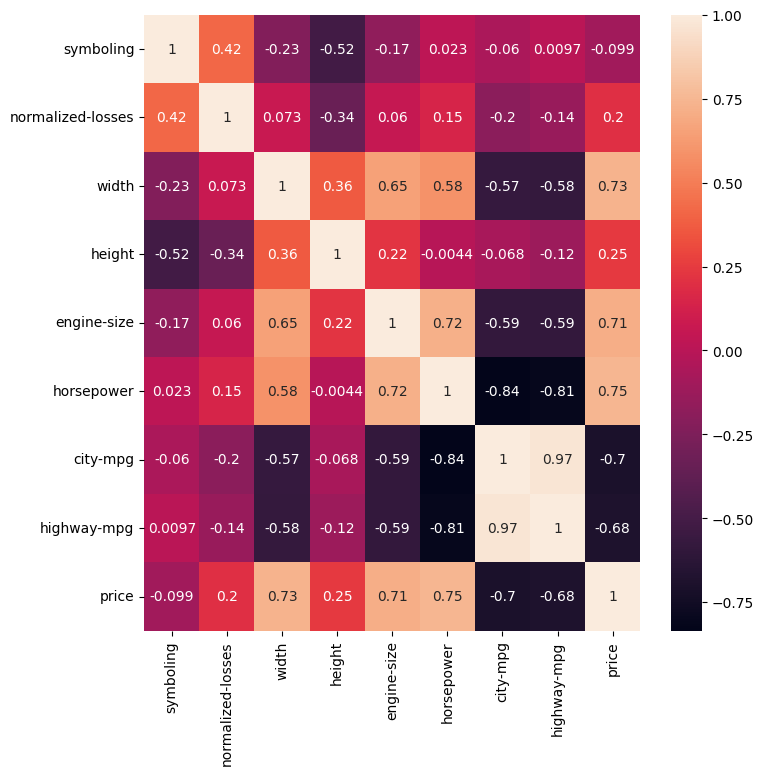

In [27]:
plt.figure(figsize=(8,8))
sns.heatmap(df_num.corr(),annot=True)
plt.show()

In [28]:
df_new = pd.concat([df_num,df_cat],axis = 1)

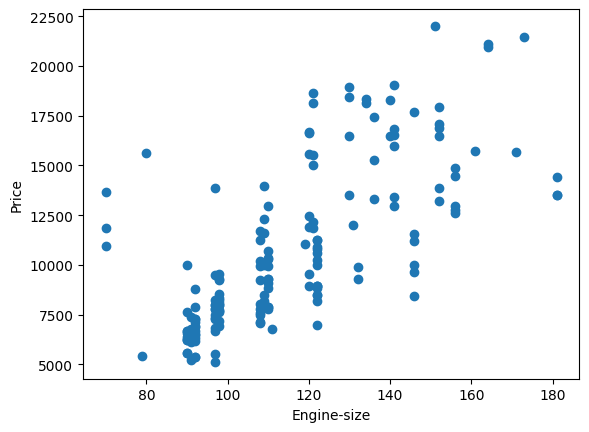

In [29]:
plt.scatter(df_new['engine-size'],df_new['price'])
plt.xlabel("Engine-size")
plt.ylabel("Price")
plt.show()

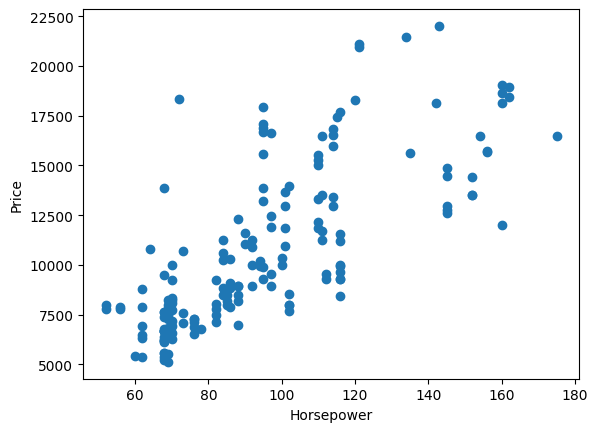

In [30]:
plt.scatter(df_new['horsepower'],df_new['price'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()

<Axes: xlabel='fuel-type', ylabel='price'>

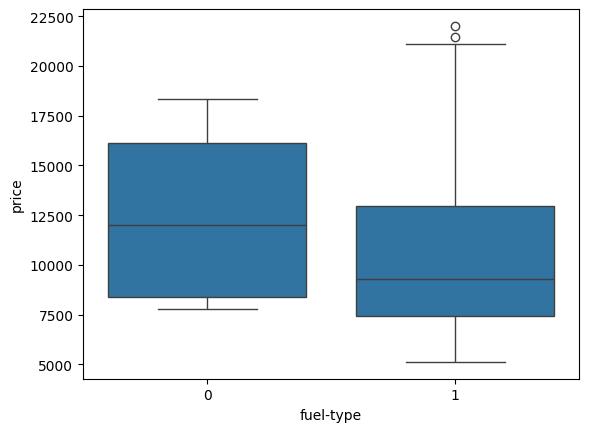

In [31]:
sns.boxplot(x ='fuel-type',y='price',data=df_new)

In [32]:
from sklearn.preprocessing import MinMaxScaler
for col in df_new.columns:
  mx = MinMaxScaler()
  df_new[col] = mx.fit_transform(df_new[[col]])

In [33]:
from sklearn.preprocessing import StandardScaler
for col in df_new:
  ss = StandardScaler()
  df_new[col] = ss.fit_transform(df_new[[col]])

In [34]:
num_cols = df.select_dtypes(include=np.number).columns
num_cols

Index(['symboling', 'normalized-losses', 'width', 'height', 'engine-size',
       'horsepower', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

In [35]:
df_new["area"] = df_new["width"] * df_new["height"]

In [36]:
df_new.head()

,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price,make,fuel-type,body-style,drive-wheels,engine-location,engine-type,area
0,1.832417,-0.075966,-0.881686,-2.058127,0.603756,0.570548,-0.906877,-0.808135,0.687769,-2.098814,0.300537,-3.205508,1.443376,0.0,-2.522216,1.814623
1,1.832417,-0.075966,-0.881686,-2.058127,0.603756,0.570548,-0.906877,-0.808135,1.431521,-2.098814,0.300537,-3.205508,1.443376,0.0,-2.522216,1.814623
2,0.162991,-0.075966,0.050844,-0.564967,1.527908,2.100501,-1.266647,-0.979711,1.431521,-2.098814,0.300537,-0.792453,1.443376,0.0,2.419865,-0.028725
3,0.997704,1.676334,0.517109,0.223091,-0.278389,0.250325,-0.367221,-0.293406,0.800383,-1.913978,0.300537,0.414075,-0.433013,0.0,-0.051175,0.115362
4,0.997704,1.676334,0.650327,0.223091,0.855797,0.712869,-1.446532,-1.666016,1.666650,-1.913978,0.300537,0.414075,-2.309401,0.0,-0.051175,0.145082


In [37]:
#  for confidence checking we use heat map

ML LAB 4

In [38]:
df=pd.read_csv("/content/Automobile_data (2).csv")

In [39]:
df.head()

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,?,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450


In [40]:
df["normalized-losses"].replace("?",np.nan,inplace=True)

/tmp/ipykernel_3218/1267431917.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["normalized-losses"].replace("?",np.nan,inplace=True)


In [41]:
df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


In [42]:
df["normalized-losses"] = pd.to_numeric(
    df["normalized-losses"],
    errors="coerce"
)

m=df["normalized-losses"].mean()
print("Mean of normalized-losses : ",m)
df["normalized-losses"].fillna(m,inplace=True)

Mean of normalized-losses :  122.0


/tmp/ipykernel_3218/1123594234.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["normalized-losses"].fillna(m,inplace=True)


In [43]:
df.isnull().sum()

,0
symboling,0
normalized-losses,0
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


In [44]:
#replace ? with null values in "horsepower" column permanently
df["horsepower"].replace("?",np.nan,inplace=True)
#change the datatype of df["horsepower"] column from object to float
#permanently
df["horsepower"]=df["horsepower"].astype("float")

/tmp/ipykernel_3218/33509820.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["horsepower"].replace("?",np.nan,inplace=True)


In [45]:
df.isnull().sum()

,0
symboling,0
normalized-losses,0
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


In [46]:
m=df["horsepower"].mean()
print("Mean of horsepower : ",m)
df["horsepower"].fillna(m,inplace=True)

Mean of horsepower :  104.25615763546799


/tmp/ipykernel_3218/1164251145.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["horsepower"].fillna(m,inplace=True)


In [47]:
df_num=df.select_dtypes(["int64","float64"])#hold to int and float type data
df_cat=df.select_dtypes(object)#hold object type data

In [48]:
from sklearn.preprocessing import LabelEncoder
for col in df_cat :
    le=LabelEncoder() #create the object of LabelEncoder class
    df_cat[col]=le.fit_transform(df_cat[col])

In [49]:
df_cat.head()

,make,fuel-type,body-style,drive-wheels,engine-location,engine-type
0,0,1,0,2,0,0
1,0,1,0,2,0,0
2,0,1,2,2,0,5
3,1,1,3,1,0,3
4,1,1,3,0,0,3


In [50]:
df_new=pd.concat([df_num,df_cat],axis=1) #axis=1 column wise
df_new.head()

,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price,make,fuel-type,body-style,drive-wheels,engine-location,engine-type
0,3,122.0,64.1,48.8,130,111.0,21,27,13495,0,1,0,2,0,0
1,3,122.0,64.1,48.8,130,111.0,21,27,16500,0,1,0,2,0,0
2,1,122.0,65.5,52.4,152,154.0,19,26,16500,0,1,2,2,0,5
3,2,164.0,66.2,54.3,109,102.0,24,30,13950,1,1,3,1,0,3
4,2,164.0,66.4,54.3,136,115.0,18,22,17450,1,1,3,0,0,3


In [51]:
X=df_new.drop("price",axis=1) #apart from price, all columns hold in X variable
Y=df_new["price"] #output variable
# axis = 1 means remove one columns
# axis = 0 means remove one rows
# if we does not defined axis then by default it is 0

In [52]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,
                                              random_state=1)

In [53]:
x = print(X_train.shape,X_test.shape)
y = print(Y_train.shape,Y_test.shape)

(143, 14) (62, 14)
(143,) (62,)


In [54]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
X_train=ss.fit_transform(X_train)
X_test=ss.transform(X_test)

In [55]:
X_train

array([[ 1.69785729,  0.02383412,  0.12469565, ...,  1.17275014,
        -0.14638501,  0.00639503],
       [-1.42488988,  0.02383412,  0.21756793, ...,  1.17275014,
        -0.14638501, -2.73707423],
       [-0.64420309, -1.38767531, -1.12908013, ..., -2.35784501,
        -0.14638501,  0.00639503],
       ...,
       [ 1.69785729,  0.7123753 ,  2.07501352, ...,  1.17275014,
        -0.14638501,  1.83537454],
       [ 0.91717049, -1.31882119, -1.03620785, ..., -2.35784501,
        -0.14638501,  0.92088479],
       [-0.64420309, -0.52699883, -0.38610189, ..., -0.59254744,
        -0.14638501,  0.00639503]])

In [56]:
from sklearn.linear_model import LinearRegression

In [57]:
lr=LinearRegression() # Initializing the model..

In [58]:
lr.fit(X_train,Y_train) # training start hua

LinearRegression()

In [59]:
y_pred = lr.predict(X_test) # testing

In [60]:
y_pred[:10]

array([ 6147.97177535,  6877.02018581,  5163.92272988,  6529.64152282,
        9097.48416127, 26360.34172002,  7459.86435141,   877.82049881,
        5144.01614104, 13519.72327075])

ML LAB 5

In [61]:
lr.score(X_train,Y_train)

0.8504573774895474

In [62]:
lr.coef_

array([   57.81895665,    44.47885193,  1700.08139295,   918.27940669,
        4046.25518791,  -450.43882012,  1968.72478882, -2781.47379917,
       -1253.87858019,  -178.99929397,  -149.85563859,  1058.52249069,
        2352.26450278,   309.65276269])

In [63]:
lr.score(X_test,Y_test)

0.7965566780397384

In [64]:
dict={'features':X.columns,'Slope':lr.coef_}
df1=pd.DataFrame(dict)
df1

,features,Slope
0,symboling,57.818957
1,normalized-losses,44.478852
2,width,1700.081393
3,height,918.279407
4,engine-size,4046.255188
5,horsepower,-450.438820
6,city-mpg,1968.724789
7,highway-mpg,-2781.473799
8,make,-1253.878580
9,fuel-type,-178.999294


In [65]:
from sklearn.linear_model import Lasso

In [66]:
for i in range(200,1001,50): #start=200 stop=1001-1=1000 step=+50
    #create the object of Lasso class , passing the value of lambda
    l1=Lasso(i) #first i=200 , next i=250 ......
    #automatic write formula RSS+i*sum(abs(all coef))
    #train the model with 70% data using Lasso class , use fit() inbuilt
    #method of Lasso class
    l1.fit(X_train,Y_train)
    print("Value of Lambda : ",i)
    #check training score
    print("Training Score : ",l1.score(X_train,Y_train))
    #check testing score
    print("Testing Score : ",l1.score(X_test,Y_test))

Value of Lambda :  200
Training Score :  0.8410262816516455
Testing Score :  0.8111395722615142
Value of Lambda :  250
Training Score :  0.8385340173594726
Testing Score :  0.8105498997329942
Value of Lambda :  300
Training Score :  0.8354878961834389
Testing Score :  0.8094641048334433
Value of Lambda :  350
Training Score :  0.8319938320056115
Testing Score :  0.8079346980993205
Value of Lambda :  400
Training Score :  0.8284657641792199
Testing Score :  0.8061490778483928
Value of Lambda :  450
Training Score :  0.8249546529678113
Testing Score :  0.8041489036760304
Value of Lambda :  500
Training Score :  0.8210304998885254
Testing Score :  0.8017878944315399
Value of Lambda :  550
Training Score :  0.8166932955129319
Testing Score :  0.7990660335452213
Value of Lambda :  600
Training Score :  0.8119430443772861
Testing Score :  0.7959832844784963
Value of Lambda :  650
Training Score :  0.8067797434912503
Testing Score :  0.7925396011412089
Value of Lambda :  700
Training Score : 

In [67]:
l1.coef_

array([  -0.        ,    0.        , 1149.39028092,    0.        ,
       4149.53419025,    0.        ,   -0.        , -441.14217416,
         -0.        ,   -0.        ,   -0.        ,  376.53222035,
       1077.64509062,    0.        ])

In [68]:
df1['Slope_Lasso']=l1.coef_
df1

,features,Slope,Slope_Lasso
0,symboling,57.818957,-0.000000
1,normalized-losses,44.478852,0.000000
2,width,1700.081393,1149.390281
3,height,918.279407,0.000000
4,engine-size,4046.255188,4149.534190
5,horsepower,-450.438820,0.000000
6,city-mpg,1968.724789,-0.000000
7,highway-mpg,-2781.473799,-441.142174
8,make,-1253.878580,-0.000000
9,fuel-type,-178.999294,-0.000000


In [69]:
lasso_model = Lasso(alpha= 200)

In [70]:
lasso_model.fit(X_train, Y_train)

Lasso(alpha=200)

In [71]:
lasso_pred = lasso_model.predict(X_test)

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE :", mean_absolute_error(Y_test, lasso_pred))
print("MSE :", mean_squared_error(Y_test, lasso_pred))
print("R² Score :", r2_score(Y_test, lasso_pred))

MAE : 2350.473190835319
MSE : 11380696.984090814
R² Score : 0.8111395722615142


In [73]:
from sklearn.linear_model import Ridge

In [74]:
for i in range(0,51): #start=0 stop=51-1=50 step=+1
    #create the object of Ridge means L2 and passing the value of lambda
    l2=Ridge(i)
    #train the model with 70% data using Ridge class , use fit() inbuilt
    #method of Ridge class
    l2.fit(X_train,Y_train)
    print("Value of Lambda : ",i)
    #check training score
    print("Training Score : ",l2.score(X_train,Y_train))
    #check testing score
    print("Testing Score : ",l2.score(X_test,Y_test))

Value of Lambda :  0
Training Score :  0.8504573774895473
Testing Score :  0.7965566780397383
Value of Lambda :  1
Training Score :  0.8502107737350233
Testing Score :  0.7997849983168293
Value of Lambda :  2
Training Score :  0.849720842460161
Testing Score :  0.8020904988940025
Value of Lambda :  3
Training Score :  0.8491421996271185
Testing Score :  0.8038550529198802
Value of Lambda :  4
Training Score :  0.8485240352668717
Testing Score :  0.8052538108138244
Value of Lambda :  5
Training Score :  0.8478855977809376
Testing Score :  0.8063836531598355
Value of Lambda :  6
Training Score :  0.8472358385089226
Testing Score :  0.8073052711461921
Value of Lambda :  7
Training Score :  0.8465795576778711
Testing Score :  0.808060017457221
Value of Lambda :  8
Training Score :  0.8459196258570562
Testing Score :  0.8086777500683582
Value of Lambda :  9
Training Score :  0.8452578949328051
Testing Score :  0.8091809348336709
Value of Lambda :  10
Training Score :  0.8445956184203912
Tes

In [75]:
l2.coef_

array([-177.69912588,   41.39428824, 1352.23613159,  689.29736461,
       2369.91729134,  790.35877258, -420.15470382, -844.56285491,
       -905.50722167, -557.79711291, -287.11557748,  981.74393699,
       1527.98348191,  414.27342682])

In [76]:
df1['Slope_Ridge']=l2.coef_
df1

,features,Slope,Slope_Lasso,Slope_Ridge
0,symboling,57.818957,-0.000000,-177.699126
1,normalized-losses,44.478852,0.000000,41.394288
2,width,1700.081393,1149.390281,1352.236132
3,height,918.279407,0.000000,689.297365
4,engine-size,4046.255188,4149.534190,2369.917291
5,horsepower,-450.438820,0.000000,790.358773
6,city-mpg,1968.724789,-0.000000,-420.154704
7,highway-mpg,-2781.473799,-441.142174,-844.562855
8,make,-1253.878580,-0.000000,-905.507222
9,fuel-type,-178.999294,-0.000000,-557.797113


In [77]:
ridge_model = Ridge(alpha= 12)

In [78]:
ridge_model.fit(X_train, Y_train)

Ridge(alpha=12)

In [79]:
ridge_pred = ridge_model.predict(X_test)

In [80]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE :", mean_absolute_error(Y_test, ridge_pred))
print("MSE :", mean_squared_error(Y_test, ridge_pred))
print("R² Score :", r2_score(Y_test, ridge_pred))

MAE : 2347.6119258273975
MSE : 11439700.22724082
R² Score : 0.8101604250480486


In [81]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        2465.395028223579,
        2346.9710123689783,
        2350.473190835319
    ],
    "MSE": [
        12262833.694863686,
        11433097.715870142,
        11380696.984090814
    ],
    "R2 Score": [
        0.7965006870725597,
        0.8102699924254559,
        0.8111395722615142
    ]
})

# Display the comparison table
comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,2465.395028,1.226283e+07,0.796501
1,Ridge Regression,2346.971012,1.143310e+07,0.810270
2,Lasso Regression,2350.473191,1.138070e+07,0.811140


ML LAB 6

In [82]:
comparison = pd.DataFrame({ "Actual": Y_test, "Predicted": y_pred })
comparison.head(10)

,Actual,Predicted
78,6669,6147.971775
97,7999,6877.020186
151,6338,5163.922730
44,10000,6529.641523
40,10295,9097.484161
67,25552,26360.341720
98,8249,7459.864351
18,5151,877.820499
152,6488,5144.016141
62,10245,13519.723271


In [83]:
from sklearn.metrics import mean_absolute_error

In [84]:
mae = mean_absolute_error(Y_test, y_pred)
print("Mean Absolute Error:", mae)

Mean Absolute Error: 2464.0068217581615


In [85]:
from sklearn.metrics import mean_squared_error

In [86]:
mse = mean_squared_error(Y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 12259459.688784504


In [92]:
import math
rmse = math.sqrt(mse)
print("Root Mean Squared Error", rmse)

Root Mean Squared Error 3501.3511233214676


In [87]:
from sklearn.metrics import r2_score

In [88]:
r2 = r2_score(Y_test, y_pred)
print("R² Score:", r2)

R² Score: 0.7965566780397384
